# 04. Comparación de movilidad durante incidencias de Rodalies

## 1. Objetivo y metodología

En este notebook analizamos cómo varían los desplazamientos entre municipios durante dos incidencias documentadas de Rodalies: el **7 de febrero de 2025 (Y25-002)**, relacionada con la línea R1 en el Maresme, y el **5 de junio de 2025 (Y25-013)**.

Para identificar posibles cambios en la movilidad, comparamos los viajes registrados durante estas incidencias con los valores habituales, utilizando la mediana de los días comparables definida en el Notebook 02.

Se seleccionan días del mismo día de la semana dentro de una ventana de **42 días anteriores y posteriores** a cada incidencia, excluyendo fines de semana, festivos oficiales de Cataluña, julio, agosto y fechas con incidencias registradas. Se requieren al menos tres días válidos para calcular la referencia. Además, se realiza una comparación utilizando únicamente los 42 días anteriores para evaluar las diferencias entre ambos enfoques.

El análisis permite identificar aumentos y disminuciones de movilidad y estudiar su distribución territorial. Sin embargo, los datos de Telefónica incluyen desplazamientos de todos los medios de transporte, por lo que **no es posible determinar qué cambios corresponden específicamente a pasajeros de Rodalies ni establecer una relación causal directa con las incidencias ferroviarias**.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import duckdb
import holidays
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "data/processed/telefonica/M2.parquet").is_file())
DATA_DIR = PROJECT_ROOT / "data"
M2_PATH = DATA_DIR / "processed/telefonica/M2.parquet"
INCIDENCIAS_PATH = DATA_DIR / "raw/rodalies/RMOVE_Incidencias_Barcelona_Jul2024_Ago2025_v07.xlsx"
con = duckdb.connect()
festivos_cat = holidays.country_holidays("ES", subdiv="CT", years=[2023, 2024, 2025])
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from analysis.rmove_indicators import (
    cargar_relaciones, calcular_indicadores, comparar_relaciones,
    seleccionar_controles, evaluar_mediana, MESES_EXCLUIDOS,
)
print("M2 encontrado:", M2_PATH.exists(), "| Excel encontrado:", INCIDENCIAS_PATH.exists())
from analysis.rmove_cases import (
    ficha_incidencia, evaluar_disponibilidad, analizar_robustez,
    conclusiones_caso, exportar_caso,
)

M2 encontrado: True | Excel encontrado: True


## 2. Incidencias documentadas

Para estudiar las variaciones de movilidad asociadas a incidencias de Rodalies, se han seleccionado dos episodios del registro histórico, correspondientes al **7 de febrero de 2025 (Y25-002)** y al **5 de junio de 2025 (Y25-013)**. Para ambos se dispone de información sobre las fechas, líneas y tramos afectados, horarios y características de las incidencias.

La incidencia del **7 de febrero** se produjo en el túnel entre Barcelona Sants y Plaça de Catalunya y afectó a varias líneas de Rodalies. El análisis se centra en las relaciones origen-destino del Maresme con Barcelona para estudiar posibles alteraciones en los desplazamientos. También se considera la coincidencia con otro episodio de la R2 registrado ese mismo día.

Para la incidencia del **5 de junio**, el análisis se centra en las relaciones origen-destino del corredor sur de Barcelona, con especial atención a las variaciones de movilidad entre los municipios seleccionados.

En ambos casos, se utiliza la información documentada en el registro de incidencias y se tienen en cuenta sus limitaciones, así como la posible influencia de otros acontecimientos sobre la movilidad. El objetivo es identificar cambios territoriales coincidentes con los episodios ferroviarios, sin atribuirles directamente su causa.

In [ ]:
incidencias = pd.read_excel(INCIDENCIAS_PATH, sheet_name="Incidencias Barcelona")

incidencias["Fecha"] = pd.to_datetime(incidencias["Fecha"])

fechas_con_incidencias = set(incidencias["Fecha"].dt.normalize().dropna())

ids_seleccionados = ["Y25-002", "Y25-013"]

incidencias_seleccionadas = incidencias.loc[incidencias["ID"].isin(ids_seleccionados)].sort_values("Fecha")

display(incidencias_seleccionadas[["ID", "Fecha", "Líneas afectadas", "Lugar / tramo",
    "Causa documentada", "Afectación documentada", "Horario / duración", "Notas y cautelas", "URL verificable"]])

ficha_febrero = ficha_incidencia(incidencias, "Y25-002")

ficha_junio = ficha_incidencia(incidencias, "Y25-013")

output_dir = PROJECT_ROOT / "data/processed/rmove"

,ID,Fecha,Líneas afectadas,Lugar / tramo,Causa documentada,Afectación documentada,Horario / duración,Notas y cautelas,URL verificable
84,Y25-002,2025-02-07,R1; R3; R4; R7,Barcelona Sants–Plaça de Catalunya,Fallo en la infraestructura / señalización del...,Circulación por vía única y frecuencias reduci...,Desde antes de 07:00; resuelta ~10:15,El registro parlamentario atribuye a esta afec...,https://beteve.cat/mobilitat/divendres-negre-r...
95,Y25-013,2025-06-05,R1; R2; R3; R4,"Túnel ferroviario de Barcelona, cerca de Plaça...",Tren averiado en el túnel,Alteraciones en varias líneas centrales; 155 t...,14:25–16:14 (registro oficial),Una de las mayores afectaciones documentadas a...,https://www.3cat.cat/3catinfo/el-mapa-dels-ret...


## 3. Funciones generales reutilizables

In [3]:
def cargar_od(origen, destino, nombre):
    return cargar_relaciones(con, M2_PATH, {nombre: (origen, destino)})

def cargar_totales(fecha, ventana=56):
    datos = con.execute("""
        SELECT day, SUM(viajes) AS viajes_observados,
               COUNT(*) AS registros, AVG(viajes) AS viajes_por_registro,
               COUNT(DISTINCT (municipio_origen, municipio_destino)) AS n_od
        FROM read_parquet(?) WHERE day BETWEEN ? AND ?
        AND municipio_origen<>municipio_destino GROUP BY day ORDER BY day
    """, [str(M2_PATH), (fecha-pd.Timedelta(days=ventana)).date(),
          (fecha+pd.Timedelta(days=ventana)).date()]).df()
    datos["day"] = pd.to_datetime(datos["day"])
    return datos

def tabla_cobertura(datos, fecha):
    controles = seleccionar_controles(datos, fecha, fechas_con_incidencias, festivos_cat)
    dia = datos.loc[datos["day"].eq(fecha)]
    if dia.empty or controles.empty:
        return pd.DataFrame()
    filas = []
    for campo in ["viajes_observados", "registros", "n_od", "viajes_por_registro"]:
        observado = dia[campo].iloc[0]
        mediana = controles[campo].median()
        filas.append({"Indicador": campo, "Observado": observado, "Mediana controles": mediana,
                      "Variacion (%)": 100*(observado/mediana-1) if mediana>0 else np.nan,
                      "N controles": len(controles)})
    return pd.DataFrame(filas)
def graficar_variacion(tabla, titulo, alto=7):
    orden = tabla.sort_values("variacion_observada_pct")
    fig, ax = plt.subplots(figsize=(12, alto))
    ax.barh(orden["Relacion"], orden["variacion_observada_pct"],
            color=["#b64026" if v<0 else "#087e86" for v in orden["variacion_observada_pct"]])
    ax.axvline(0, color="black", linewidth=1)
    ax.set(xlabel="Variación de viajes frente a la mediana (%)", ylabel="", title=titulo)
    ax.invert_yaxis(); ax.grid(axis="x", alpha=.25)
    plt.tight_layout(); plt.show()

def graficar_cobertura(datos, fecha, titulo):
    comparables = seleccionar_controles(datos, fecha, fechas_con_incidencias, festivos_cat)
    dias = datos.loc[datos["day"].dt.day_of_week.eq(fecha.day_of_week)]
    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    for ax, campo in zip(axes, ["viajes_observados", "registros", "n_od"]):
        ax.plot(dias["day"], dias[campo], color="#798b96", marker="o", label="Mismo día semanal")
        ax.scatter(comparables["day"], comparables[campo], color="#087e86", label="Controles usados")
        ax.axvline(fecha, color="#e8700a", linestyle="--", label="Incidencia")
        ax.set_ylabel(campo); ax.grid(alpha=.25)
    axes[0].set_title(titulo); axes[0].legend()
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

def graficar_evolucion(movilidad, fecha, nombres):
    fig, axes = plt.subplots(len(nombres), 1, figsize=(12, 4*len(nombres)), sharex=True, squeeze=False)
    for ax, nombre in zip(axes[:, 0], nombres):
        grupo = movilidad.loc[movilidad["Relacion"].eq(nombre)].sort_values("day")
        dias = pd.date_range(fecha-pd.Timedelta(days=21), fecha+pd.Timedelta(days=21))
        refs = pd.DataFrame([calcular_indicadores(grupo, d, fechas_con_incidencias, festivos_cat)[0] for d in dias])
        medianas = refs["mediana_viajes_controles"].where(refs["estado"].eq("ok"))
        ax.plot(dias, refs["viajes_observados"], label="Observados", marker="o", markersize=3)
        ax.plot(dias, medianas, linestyle="--", label="Mediana retrospectiva")
        ax.axvline(fecha, color="#e8700a", linestyle=":")
        ax.set(title=nombre, ylabel="Viajes"); ax.legend(); ax.grid(alpha=.25)
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 4. Primer caso: 7 de febrero de 2025 · R1/Maresme

### 4.1. Descripción y ámbito de estudio

El 7 de febrero de 2025 se registró una incidencia ferroviaria (Y25-002) en el túnel entre Barcelona Sants y Plaça de Catalunya, causada por un problema de infraestructura y señalización. La circulación quedó limitada a una sola vía, provocando una reducción de las frecuencias en varias líneas de Rodalies.

Para estudiar las posibles variaciones de movilidad en el corredor del Maresme, seleccionamos cinco municipios: **Barcelona, Mataró, Premià de Mar, El Masnou y Arenys de Mar**. Se analizan inicialmente las 20 relaciones origen-destino posibles entre estos municipios, considerando ambos sentidos de desplazamiento.

Antes del análisis, comprobamos la disponibilidad y calidad de los datos. Para seleccionar una relación se requieren al menos 300 días con observaciones en 2024, una media mínima de 100 viajes diarios, datos válidos para el día de la incidencia y al menos tres días comparables para calcular la referencia.

Las relaciones que no cumplen estos criterios quedan excluidas del análisis. No se sustituyen los datos ausentes por ceros, para evitar introducir distorsiones en los resultados.

In [22]:

# Fecha de la incidencia
fecha_incidencia_febrero = pd.Timestamp(ficha_febrero["fecha"])

# Municipios seleccionados para el análisis del corredor del Maresme
municipios_maresme = {
    "08019": "Barcelona",
    "08121": "Mataró",
    "08172": "Premià de Mar",
    "08118": "El Masnou",
    "08006": "Arenys de Mar"
}

# Generar todas las relaciones origen-destino dirigidas (5 × 4 = 20)
relaciones_maresme = {
    f"{no} → {nd}": (o, d)
    for o, no in municipios_maresme.items()
    for d, nd in municipios_maresme.items()
    if o != d
}

# Cargar los viajes y evaluar la disponibilidad de cada relación
movilidad_maresme_candidata = cargar_relaciones(
    con, M2_PATH, relaciones_maresme
)

disponibilidad_febrero = evaluar_disponibilidad(
    movilidad_maresme_candidata,
    relaciones_maresme,
    fecha_incidencia_febrero,
    fechas_con_incidencias,
    festivos_cat
)

# Seleccionar únicamente las relaciones que cumplen los criterios
nombres_validos = disponibilidad_febrero.loc[
    disponibilidad_febrero["seleccionada"], "Relacion"
]

movilidad_febrero = movilidad_maresme_candidata.loc[
    movilidad_maresme_candidata["Relacion"].isin(nombres_validos)
].copy()

# Resumen de la selección
n_candidatas = len(relaciones_maresme)
n_seleccionadas = len(nombres_validos)
n_excluidas = n_candidatas - n_seleccionadas

print(f"Incidencia: {fecha_incidencia_febrero:%d/%m/%Y}")
print(f"Municipios analizados: {len(municipios_maresme)}")
print(f"Relaciones candidatas: {n_candidatas}")
print(f"Relaciones seleccionadas: {n_seleccionadas}")
print(f"Relaciones excluidas: {n_excluidas}")

# Mostrar únicamente las relaciones excluidas, si existen
if n_excluidas > 0:
    print("\nRelaciones excluidas por los criterios de disponibilidad:")

    columnas = [
        "Relacion",
        "dias_observados_2024",
        "viajes_medios_2024"
    ]

    display(
        disponibilidad_febrero.loc[
            ~disponibilidad_febrero["seleccionada"], columnas
        ].round(2)
    )


Incidencia: 07/02/2025
Municipios analizados: 5
Relaciones candidatas: 20
Relaciones seleccionadas: 18
Relaciones excluidas: 2

Relaciones excluidas por los criterios de disponibilidad:


,Relacion,dias_observados_2024,viajes_medios_2024
15,El Masnou → Arenys de Mar,365,89.92
19,Arenys de Mar → El Masnou,365,97.12


### 4.2. Mediana de viernes comparables y variación de viajes

En este apartado analizamos cómo variaron los desplazamientos entre los municipios seleccionados del Maresme durante la incidencia del 7 de febrero de 2025.

Para cada relación origen-destino, comparamos los viajes observados ese día con la **mediana de los viernes comparables**, calculada utilizando los 42 días anteriores y posteriores a la incidencia, excluyendo festivos y fechas con incidencias registradas.

A partir de esta comparación, calculamos la variación absoluta y porcentual de los viajes para identificar las relaciones que presentan mayores aumentos o disminuciones respecto a su comportamiento habitual.

También se utiliza la **banda intercuartílica (P25–P75)** para representar la variabilidad de los días de referencia y contextualizar las diferencias observadas, sin asumir que estas se deban directamente a la incidencia ferroviaria.

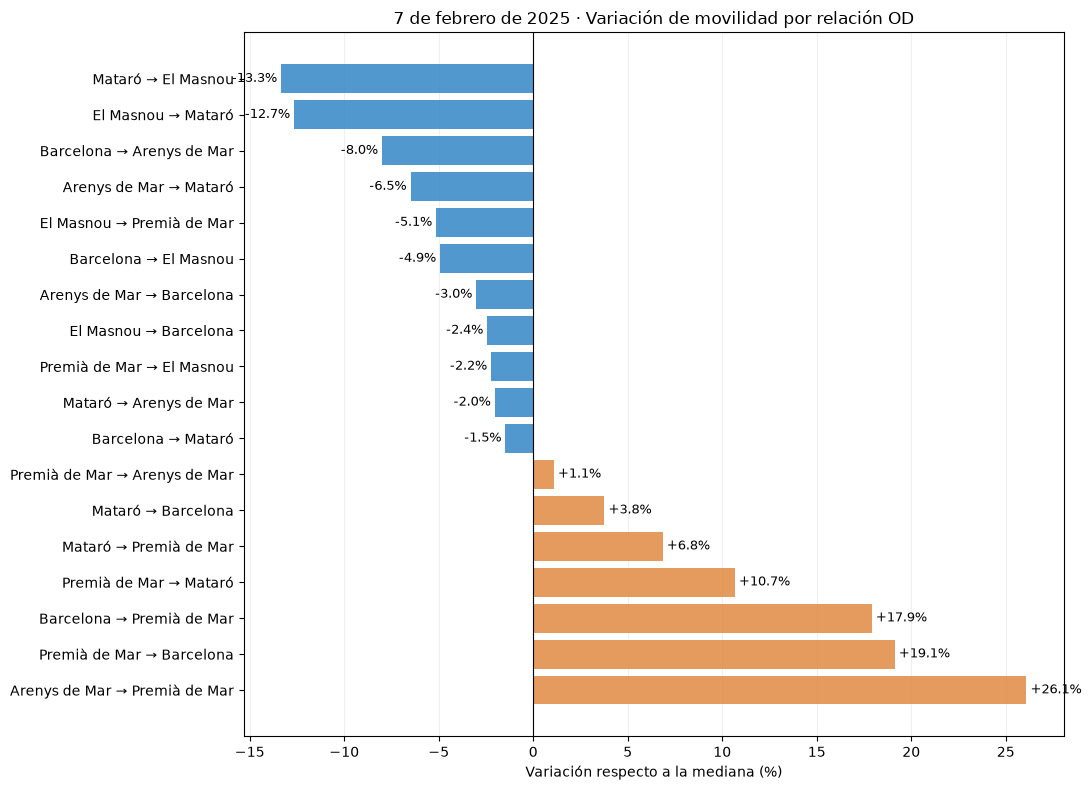

In [24]:

# Ordenar las relaciones según su variación porcentual
orden = resultados_febrero.sort_values("variacion_observada_pct")

# Colores: azul para disminuciones, naranja para aumentos
colores = [
    "#3286C6" if v < 0 else "#E18A40"
    for v in orden["variacion_observada_pct"]
]

fig, ax = plt.subplots(figsize=(11, 8))

# Representar las variaciones porcentuales
barras = ax.barh(
    orden["Relacion"],
    orden["variacion_observada_pct"],
    color=colores,
    alpha=0.85
)

# Línea vertical que representa ausencia de variación
ax.axvline(0, color="black", linewidth=0.8)

# Mostrar el porcentaje al final de cada barra
ax.bar_label(
    barras,
    fmt="%+.1f%%",
    padding=3,
    fontsize=9
)

ax.invert_yaxis()
ax.set(
    xlabel="Variación respecto a la mediana (%)",
    title="7 de febrero de 2025 · Variación de movilidad por relación OD"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


El 7 de febrero de 2025 se observan variaciones de movilidad heterogéneas entre los municipios analizados. Las mayores disminuciones se registran entre Mataró y El Masnou, con reducciones superiores al 12 % en ambos sentidos.

Por otro lado, destacan los aumentos en Arenys de Mar → Premià de Mar (+26,1 %) y en las conexiones entre Premià de Mar y Barcelona, con incrementos cercanos al 18–19 %.

Estos resultados muestran que los cambios de movilidad no son uniformes y que algunas relaciones presentan comportamientos diferentes según el sentido del desplazamiento. Aunque estas variaciones coinciden temporalmente con la incidencia ferroviaria, no permiten establecer una relación causal directa.

### 4.5. Conclusiones y exportación de resultados

En este apartado se resumen los principales resultados del análisis de la incidencia del 7 de febrero de 2025, destacando las relaciones origen-destino con mayores variaciones de movilidad respecto a sus valores habituales.

Además, se exportan los resultados a un archivo JSON para facilitar su posterior integración en el dashboard de R-MOVE. Este archivo incluye los viajes observados, las variaciones calculadas, la información de la incidencia y los datos complementarios utilizados para contextualizar y verificar el análisis.

Se conservan únicamente datos reales y resultados derivados de ellos, sin generar ni imputar valores de movilidad ausentes.

In [28]:

# 1. Definir los municipios del ámbito de estudio
# Las coordenadas son aproximadas y se utilizarán para el mapa del dashboard
catalogo_febrero = [
    {"codigo": "08019", "nombre": "Barcelona", "lat": 41.387, "lon": 2.170},
    {"codigo": "08121", "nombre": "Mataró", "lat": 41.538, "lon": 2.445},
    {"codigo": "08172", "nombre": "Premià de Mar", "lat": 41.491, "lon": 2.357},
    {"codigo": "08118", "nombre": "El Masnou", "lat": 41.479, "lon": 2.317},
    {"codigo": "08006", "nombre": "Arenys de Mar", "lat": 41.581, "lon": 2.551},
]

# Indicar que las coordenadas representan ubicaciones municipales aproximadas
for municipio in catalogo_febrero:
    municipio["precision"] = "Posición municipal aproximada; no es una estación"


# 2. Mostrar las principales conclusiones del análisis
print("CONCLUSIONES · 7 DE FEBRERO DE 2025\n")

for conclusion in conclusiones_caso(resultados_febrero, cobertura_febrero):
    print(f"• {conclusion}")


# 3. Exportar los resultados para su integración en el dashboard
salida_febrero = exportar_caso(
    output_dir=output_dir,
    fecha=fecha_incidencia_febrero,
    ficha=ficha_febrero,
    ambito="R1 / Maresme",
    municipios=catalogo_febrero,
    resultados=resultados_febrero,
    movilidad=movilidad_febrero,
    disponibilidad=disponibilidad_febrero,
    provincia=movilidad_provincial_febrero,
    cobertura=cobertura_febrero,
    robustez=robustez_febrero,
    sensibilidad=sensibilidad_febrero,
    fechas_incidencias=fechas_con_incidencias,
    festivos=festivos_cat,
    fuente_excel=str(INCIDENCIAS_PATH.relative_to(PROJECT_ROOT))
)

print("\nResultados exportados: incidencia_2025_02_07.json")


CONCLUSIONES · 7 DE FEBRERO DE 2025

• 18 relaciones con comparación válida: 11 por debajo de la mediana y 7 por encima.
• Menor variación: Mataró → El Masnou (-13,34 %).
• Mayor variación: Arenys de Mar → Premià de Mar (+26,09 %).
• Variación de viajes provinciales frente a sus días comparables: +0,34 %.
• Variación de registros de movilidad frente a sus días comparables: +0,21 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.

Resultados exportados: incidencia_2025_02_07.json


## 5. Segundo caso: 5 de junio de 2025 · Corredor sur

### 5.1. Descripción y ámbito de estudio

En este segundo caso analizamos las variaciones de movilidad registradas el 5 de junio de 2025, coincidiendo con la incidencia ferroviaria Y25-013 documentada en el registro histórico de Rodalies.

El estudio se centra en cinco municipios del corredor sur de Barcelona: **Barcelona, El Prat de Llobregat, Viladecans, Gavà y Castelldefels**. Se consideran inicialmente las 20 relaciones origen-destino posibles entre estos municipios, incluyendo ambos sentidos de desplazamiento.

Antes de realizar el análisis, comprobamos la disponibilidad de los datos utilizando los mismos criterios que en el caso del Maresme: al menos 300 días observados en 2024, una media mínima de 100 viajes diarios, datos válidos para el día de la incidencia y un mínimo de tres días comparables.

Las relaciones que no cumplen estos requisitos quedan excluidas del análisis, sin sustituir los datos ausentes por ceros.

In [29]:

# 1. Obtener la fecha de la incidencia desde el Excel
fecha_incidencia_junio = pd.Timestamp(ficha_junio["fecha"])

# 2. Definir los municipios del corredor sur
municipios_sur = {
    "08019": "Barcelona",
    "08169": "El Prat de Llobregat",
    "08301": "Viladecans",
    "08089": "Gavà",
    "08056": "Castelldefels"
}

# Generar las 20 relaciones origen-destino dirigidas
# entre municipios distintos
relaciones_sur_dict = {
    f"{no} → {nd}": (o, d)
    for o, no in municipios_sur.items()
    for d, nd in municipios_sur.items()
    if o != d
}

# 3. Cargar los viajes de todas las relaciones candidatas
movilidad_sur_candidata = cargar_relaciones(
    con, M2_PATH, relaciones_sur_dict
)

# 4. Evaluar qué relaciones cumplen los criterios de disponibilidad
disponibilidad_junio = evaluar_disponibilidad(
    movilidad_sur_candidata,
    relaciones_sur_dict,
    fecha_incidencia_junio,
    fechas_con_incidencias,
    festivos_cat
)

# 5. Seleccionar únicamente las relaciones válidas
nombres_validos_junio = disponibilidad_junio.loc[
    disponibilidad_junio["seleccionada"], "Relacion"
]

movilidad_junio_od = movilidad_sur_candidata.loc[
    movilidad_sur_candidata["Relacion"].isin(nombres_validos_junio)
].copy()

# Mantener este alias para compatibilidad con otras funciones
movilidad_observada = movilidad_junio_od

# 6. Mostrar un resumen de la selección
n_candidatas = len(relaciones_sur_dict)
n_seleccionadas = len(nombres_validos_junio)

print(f"Incidencia: {fecha_incidencia_junio:%d/%m/%Y}")
print(f"Municipios analizados: {len(municipios_sur)}")
print(f"Relaciones candidatas: {n_candidatas}")
print(f"Relaciones seleccionadas: {n_seleccionadas}")
print(f"Relaciones excluidas: {n_candidatas - n_seleccionadas}")

# Mostrar solo las relaciones excluidas, si existen
excluidas_junio = disponibilidad_junio.loc[
    ~disponibilidad_junio["seleccionada"],
    ["Relacion", "dias_observados_2024", "viajes_medios_2024"]
]

if not excluidas_junio.empty:
    print("\nRelaciones excluidas:")
    display(excluidas_junio.round(2))


Incidencia: 05/06/2025
Municipios analizados: 5
Relaciones candidatas: 20
Relaciones seleccionadas: 20
Relaciones excluidas: 0


### 5.2. Mediana de jueves comparables y variación de viajes

En este apartado analizamos cómo variaron los desplazamientos entre los municipios seleccionados del corredor sur durante la incidencia del 5 de junio de 2025.

Para cada relación origen-destino, comparamos los viajes observados ese día con la **mediana de los jueves comparables**, calculada utilizando los 42 días anteriores y posteriores, excluyendo festivos y fechas con incidencias registradas.

A partir de esta referencia, calculamos las variaciones absolutas y porcentuales para identificar las relaciones que presentan mayores aumentos o disminuciones respecto a su movilidad habitual.

Estos resultados permiten estudiar la distribución territorial de los cambios observados, sin atribuirlos directamente a la incidencia ferroviaria.

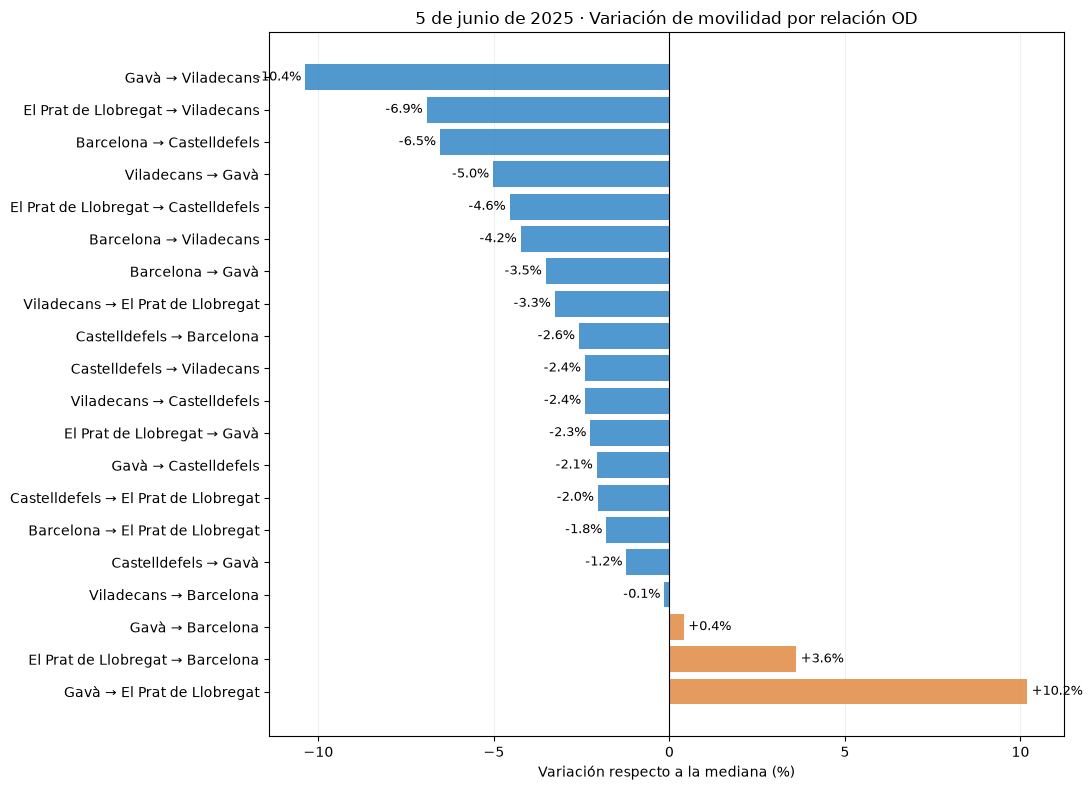

In [30]:

# 1. Calcular las variaciones respecto a la mediana
# retrospectiva de los jueves comparables (±42 días)
resultados_sur_junio = comparar_relaciones(
    movilidad_junio_od,
    fecha_incidencia_junio,
    fechas_con_incidencias,
    festivos_cat
)

# 2. Ordenar las relaciones según su variación porcentual
orden_junio = resultados_sur_junio.sort_values(
    "variacion_observada_pct"
)

# 3. Asignar colores según el sentido de la variación
# Azul: disminución | Naranja: aumento
colores = [
    "#3286C6" if v < 0 else "#E18A40"
    for v in orden_junio["variacion_observada_pct"]
]

# 4. Representar las variaciones porcentuales
fig, ax = plt.subplots(figsize=(11, 8))

barras = ax.barh(
    orden_junio["Relacion"],
    orden_junio["variacion_observada_pct"],
    color=colores,
    alpha=0.85
)

# Línea de referencia sin variación
ax.axvline(0, color="black", linewidth=0.8)

# Mostrar el porcentaje al final de cada barra
ax.bar_label(
    barras,
    fmt="%+.1f%%",
    padding=3,
    fontsize=9
)

ax.invert_yaxis()

ax.set(
    xlabel="Variación respecto a la mediana (%)",
    title="5 de junio de 2025 · Variación de movilidad por relación OD"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [31]:

# Seleccionar las 5 mayores disminuciones
mayores_caidas_junio = resultados_sur_junio.nsmallest(
    5, "variacion_observada_pct"
)

# Seleccionar los 5 mayores aumentos
mayores_aumentos_junio = resultados_sur_junio.nlargest(
    5, "variacion_observada_pct"
)

# Unir ambas selecciones sin duplicar relaciones
resumen_junio = pd.concat([
    mayores_caidas_junio,
    mayores_aumentos_junio
]).drop_duplicates(subset="Relacion")

# Conservar las columnas relevantes
resumen_junio = resumen_junio[[
    "Relacion",
    "viajes_observados",
    "mediana_viajes_controles",
    "variacion_observada_pct"
]].sort_values("variacion_observada_pct")

# Mostrar la tabla con un formato más claro
display(
    resumen_junio.style.format({
        "viajes_observados": "{:,.0f}",
        "mediana_viajes_controles": "{:,.0f}",
        "variacion_observada_pct": "{:+.2f}%"
    })
)


,Relacion,viajes_observados,mediana_viajes_controles,variacion_observada_pct
0,Gavà → Viladecans,"2,834","3,162",-10.37%
1,El Prat de Llobregat → Viladecans,"5,947","6,389",-6.92%
2,Barcelona → Castelldefels,"14,755","15,787",-6.54%
3,Viladecans → Gavà,"2,789","2,936",-5.02%
4,El Prat de Llobregat → Castelldefels,"6,289","6,589",-4.55%
15,Castelldefels → Gavà,"6,776","6,860",-1.22%
16,Viladecans → Barcelona,"17,275","17,300",-0.14%
17,Gavà → Barcelona,"11,233","11,186",+0.42%
18,El Prat de Llobregat → Barcelona,"85,445","82,461",+3.62%
19,Gavà → El Prat de Llobregat,"4,419","4,010",+10.20%


El 5 de junio de 2025 se observa una tendencia predominantemente negativa en la movilidad del corredor sur, con disminuciones en 17 de las 20 relaciones origen-destino analizadas.

Las mayores reducciones se registran en Gavà → Viladecans (−10,4 %), El Prat de Llobregat → Viladecans (−6,9 %) y Barcelona → Castelldefels (−6,5 %). Por otro lado, destacan los aumentos en Gavà → El Prat de Llobregat (+10,2 %) y El Prat de Llobregat → Barcelona (+3,6 %).

Estos resultados muestran diferencias territoriales y entre sentidos de desplazamiento. Aunque los cambios coinciden con la incidencia ferroviaria, no permiten determinar si fueron consecuencia directa de esta ni identificar los medios de transporte utilizados.

### 5.3. Conclusiones y exportación de resultados

En este apartado se resumen los principales resultados del análisis de la incidencia del 5 de junio de 2025, destacando las relaciones origen-destino con mayores variaciones de movilidad respecto a sus valores habituales.

Además, se exportan los resultados a un archivo JSON para facilitar su integración en el dashboard de R-MOVE. Este archivo incluye los viajes observados, las variaciones calculadas, la información de la incidencia y los datos complementarios necesarios para contextualizar el análisis.

Se conservan únicamente observaciones reales y estadísticas derivadas, sin imputar los datos de movilidad ausentes.

In [32]:

# 1. Calcular los indicadores complementarios para la exportación
# No se muestran sus tablas ni gráficos en el notebook
movilidad_provincial_junio = cargar_totales(
    fecha_incidencia_junio
)

cobertura_junio = tabla_cobertura(
    movilidad_provincial_junio,
    fecha_incidencia_junio
)

junio_predictivo, robustez_junio, sensibilidad_junio = analizar_robustez(
    movilidad_junio_od,
    fecha_incidencia_junio,
    fechas_con_incidencias,
    festivos_cat,
    resultados_sur_junio
)

# 2. Definir los municipios para el mapa del dashboard
# Las coordenadas representan posiciones municipales aproximadas
catalogo_junio = [
    {"codigo": "08019", "nombre": "Barcelona", "lat": 41.387, "lon": 2.170},
    {"codigo": "08169", "nombre": "El Prat de Llobregat", "lat": 41.327, "lon": 2.094},
    {"codigo": "08301", "nombre": "Viladecans", "lat": 41.315, "lon": 2.019},
    {"codigo": "08089", "nombre": "Gavà", "lat": 41.306, "lon": 2.001},
    {"codigo": "08056", "nombre": "Castelldefels", "lat": 41.281, "lon": 1.976},
]

# Aclarar que los puntos no representan estaciones ferroviarias
for municipio in catalogo_junio:
    municipio["precision"] = "Posición municipal aproximada; no es una estación"

# 3. Mostrar las conclusiones calculadas
print("CONCLUSIONES · 5 DE JUNIO DE 2025\n")

for conclusion in conclusiones_caso(
    resultados_sur_junio,
    cobertura_junio
):
    print(f"• {conclusion}")

# 4. Exportar los resultados para su uso en el dashboard
salida_junio = exportar_caso(
    output_dir=output_dir,
    fecha=fecha_incidencia_junio,
    ficha=ficha_junio,
    ambito="Corredor sur",
    municipios=catalogo_junio,
    resultados=resultados_sur_junio,
    movilidad=movilidad_junio_od,
    disponibilidad=disponibilidad_junio,
    provincia=movilidad_provincial_junio,
    cobertura=cobertura_junio,
    robustez=robustez_junio,
    sensibilidad=sensibilidad_junio,
    fechas_incidencias=fechas_con_incidencias,
    festivos=festivos_cat,
    fuente_excel=str(INCIDENCIAS_PATH.relative_to(PROJECT_ROOT)),
    descripcion="Incidencia ferroviaria en Barcelona"
)

print("\nResultados exportados: incidencia_2025_06_05.json")


CONCLUSIONES · 5 DE JUNIO DE 2025

• 20 relaciones con comparación válida: 17 por debajo de la mediana y 3 por encima.
• Menor variación: Gavà → Viladecans (-10,37 %).
• Mayor variación: Gavà → El Prat de Llobregat (+10,20 %).
• Variación de viajes provinciales frente a sus días comparables: -2,11 %.
• Variación de registros de movilidad frente a sus días comparables: -1,38 %.
• Las cifras son diferencias descriptivas frente a días comparables. No demuestran efectos causales de Rodalies ni validan un detector de incidencias.

Resultados exportados: incidencia_2025_06_05.json


## 6. Conclusiones generales

El análisis de las incidencias del **7 de febrero y el 5 de junio de 2025** permite identificar variaciones en los patrones de movilidad entre los municipios estudiados, utilizando como referencia la mediana de los días comparables.

En el **caso del Maresme**, se observan tanto aumentos como disminuciones de viajes. Destacan las reducciones entre Mataró y El Masnou, superiores al 12 % en ambos sentidos, y los incrementos en las conexiones de Premià de Mar con Barcelona, cercanos al 18–19 %.

En el **corredor sur**, predominan las disminuciones, presentes en 17 de las 20 relaciones analizadas. Las mayores se registran entre Gavà y Viladecans (−10,4 %) y entre El Prat de Llobregat y Viladecans (−6,9 %), aunque también se observan aumentos en algunas conexiones con El Prat.

Estos resultados muestran que las variaciones de movilidad no son uniformes y que su distribución depende del territorio y del sentido del desplazamiento. La metodología utilizada permite cuantificar estas diferencias e identificar relaciones que merecen un análisis más detallado.

No obstante, **los datos incluyen desplazamientos de todos los modos de transporte**, por lo que no es posible atribuir directamente las variaciones a las incidencias de Rodalies ni determinar si los viajeros utilizaron medios alternativos.

Los resultados obtenidos constituyen la base para su representación en el **dashboard interactivo de R-MOVE**, donde podrán explorarse las variaciones de movilidad por fecha y relación origen-destino.